# ProofWriter zero-shot: LM scoring vs DC-PMI

Following the DC-PMI demo (Holtzman et al. 2021), here we run zero-shot truth-value
classification on `tasksource/proofwriter`. Each example is a `theory` + a `question`
(a statement), and the label is one of `True` / `False` / `Unknown` (OWA).

Candidate set is the three label words. We compare:
- **LM**: `argmax_i P(label_i | theory, question)`
- **DC-PMI**: `argmax_i P(label_i | theory, question) / P(label_i | domain)`

where the domain premise is the bare answer-eliciting tail (no theory, no question),
so the prior captures the model's raw bias toward each label word.

Three Gemma sizes, configurable number of samples.

In [1]:
import os

import torch
from dotenv import load_dotenv
from huggingface_hub import login
from transformers import AutoModelForCausalLM, AutoTokenizer
from datasets import load_dataset
import matplotlib.pyplot as plt
import numpy as np
from tqdm.auto import tqdm

In [2]:
load_dotenv("secret.env")
login()

---

## Config

In [3]:
device = "cuda"

MODELS = [
    "google/gemma-3-270m-it",
    "google/gemma-3-1b-it",
    "google/gemma-3-4b-it",
]

N_SAMPLES = 100  # examples to run inference on, per model

LABELS = ["True", "False", "Unknown"]
CANDIDATES = [" True", " False", " Unknown"]  # leading space: prompt ends in ':'

In [4]:
dataset = load_dataset("tasksource/proofwriter", split="validation")
# take the first N_SAMPLES; deterministic so LM and DC-PMI see the same examples
examples = [dataset[i] for i in range(N_SAMPLES)]
examples[0]

{'id': 'AttNoneg-OWA-D0-4746',
 'maxD': 0,
 'NFact': 3,
 'NRule': 2,
 'theory': 'Charlie is blue. Charlie is cold. Dave is quiet. If someone is big and quiet then they are round. Big, rough people are round.',
 'question': 'Charlie is cold.',
 'answer': 'True',
 'QDep': 0,
 'QLen': 1.0,
 'allProofs': '@0: Charlie is blue.[(triple1)] Charlie is cold.[(triple2)] Dave is quiet.[(triple3)]',
 'config': 'depth-0'}

---

## Prompts

`make_prompt` is the full conditional context. `DOMAIN_PROMPT` is the null context
(domain premise) used for the DC-PMI prior — same answer-eliciting tail, but with the
theory and question stripped out.

In [ ]:
def make_prompt(ex):
    return (
        f"{ex['theory']}\n"
        f'Based on the above, the statement "{ex["question"]}" is '
        f"(True, False, or Unknown):"
    )

DOMAIN_PROMPT = "The statement is (True, False, or Unknown):"

print(make_prompt(examples[0]))
print("---")
print(DOMAIN_PROMPT)

Charlie is blue. Charlie is cold. Dave is quiet. If someone is big and quiet then they are round. Big, rough people are round.
Based on the above, the statement "Charlie is cold." is (True, False, or Unknown):
---
The statement is (True, False, or Unknown):


---

## Scoring

Same teacher-forced approach as the demo: append the candidate to the prompt, read the
log-softmax of each candidate token. We work in log space here (sum of token logprobs)
to stay numerically safe across the longer ProofWriter prompts.

In [6]:
@torch.no_grad()
def choice_logprob(model, tokenizer, prompt_ids, choice):
    """Sum of token logprobs of `choice` given `prompt_ids`."""
    choice_ids = tokenizer(choice, add_special_tokens=False, return_tensors="pt").input_ids[0].to(device)
    ids = torch.cat((prompt_ids, choice_ids))
    logits = model(ids.unsqueeze(0)).logits[0]
    logprobs = logits.log_softmax(-1)
    total = 0.0
    for i, token_id in enumerate(choice_ids):
        # logits at position t predict token t+1
        total += logprobs[len(prompt_ids) - 1 + i, token_id].item()
    return total

@torch.no_grad()
def evaluate_choices(model, tokenizer, prompt, choices):
    prompt_ids = tokenizer(prompt, return_tensors="pt").input_ids[0].to(device)
    return np.array([choice_logprob(model, tokenizer, prompt_ids, c) for c in choices])

In [7]:
def predict_lm(model, tokenizer, ex):
    cond = evaluate_choices(model, tokenizer, make_prompt(ex), CANDIDATES)
    return LABELS[int(cond.argmax())], cond

def predict_dcpmi(model, tokenizer, ex, prior):
    cond = evaluate_choices(model, tokenizer, make_prompt(ex), CANDIDATES)
    # DC-PMI in log space: log P(y|x,domain) - log P(y|domain)
    pmi = cond - prior
    return LABELS[int(pmi.argmax())], pmi

---

## Run all models

For each model: load it, compute the domain prior once (it's example-independent), then
run LM and DC-PMI predictions over the `N_SAMPLES` examples.

In [8]:
results = {}

for model_name in MODELS:
    print(f"\n===== {model_name} =====")
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForCausalLM.from_pretrained(model_name, dtype=torch.bfloat16).to(device)
    model.eval()

    # domain prior: P(label | domain), shared across all examples
    prior = evaluate_choices(model, tokenizer, DOMAIN_PROMPT, CANDIDATES)
    print("prior logprobs:", dict(zip(LABELS, np.round(prior, 2))))

    lm_correct, pmi_correct = 0, 0
    rows = []
    for ex in tqdm(examples, desc=model_name.split("/")[-1]):
        gold = ex["answer"]
        lm_pred, _ = predict_lm(model, tokenizer, ex)
        pmi_pred, _ = predict_dcpmi(model, tokenizer, ex, prior)
        lm_correct += lm_pred == gold
        pmi_correct += pmi_pred == gold
        rows.append((gold, lm_pred, pmi_pred))

    n = len(examples)
    results[model_name] = {
        "lm_acc": lm_correct / n,
        "dcpmi_acc": pmi_correct / n,
        "rows": rows,
    }
    print(f"LM acc = {lm_correct}/{n}   DC-PMI acc = {pmi_correct}/{n}")

    # free the GPU before the next model
    del model
    torch.cuda.empty_cache()


===== google/gemma-3-270m-it =====


Loading weights:   0%|          | 0/236 [00:00<?, ?it/s]

prior logprobs: {'True': np.float64(-9.06), 'False': np.float64(-11.06), 'Unknown': np.float64(-10.06)}


gemma-3-270m-it:   0%|          | 0/100 [00:00<?, ?it/s]

LM acc = 31/100   DC-PMI acc = 34/100

===== google/gemma-3-1b-it =====


Loading weights:   0%|          | 0/340 [00:00<?, ?it/s]

... (3 outputs left out)

Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

prior logprobs: {'True': np.float64(-5.69), 'False': np.float64(-6.88), 'Unknown': np.float64(-11.31)}


gemma-3-4b-it:   0%|          | 0/100 [00:00<?, ?it/s]

LM acc = 52/100   DC-PMI acc = 46/100


---

## Comparison

google/gemma-3-270m-it        LM=0.31  DC-PMI=0.34
google/gemma-3-1b-it          LM=0.31  DC-PMI=0.37
google/gemma-3-4b-it          LM=0.52  DC-PMI=0.46


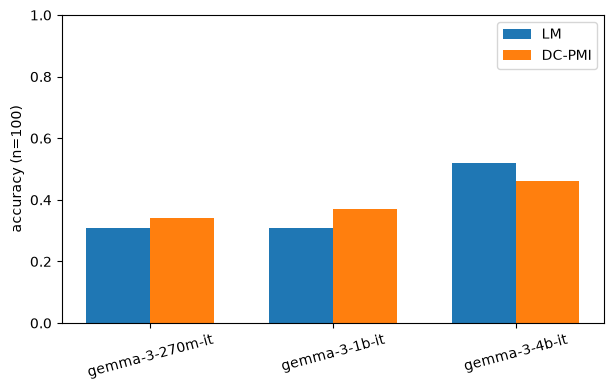

In [9]:
for model_name, r in results.items():
    print(f"{model_name:28s}  LM={r['lm_acc']:.2f}  DC-PMI={r['dcpmi_acc']:.2f}")

labels = [m.split("/")[-1] for m in MODELS]
lm_accs = [results[m]["lm_acc"] for m in MODELS]
pmi_accs = [results[m]["dcpmi_acc"] for m in MODELS]

x = np.arange(len(MODELS))
w = 0.35
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(x - w / 2, lm_accs, w, label="LM")
ax.bar(x + w / 2, pmi_accs, w, label="DC-PMI")
ax.set_xticks(x, labels, rotation=15)
ax.set_ylabel(f"accuracy (n={N_SAMPLES})")
ax.set_ylim(0, 1)
ax.legend()
fig.show()

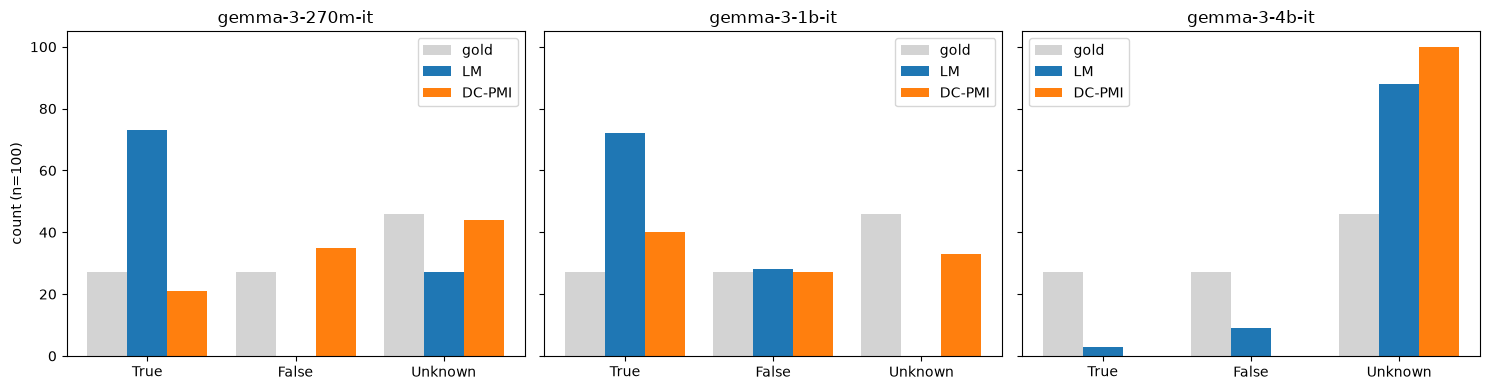

In [10]:
# Answer frequency: how often each method predicts True / False / Unknown.
# Surface-form bias shows up here as a skewed prediction distribution vs gold.
def freq(preds):
    return np.array([sum(p == lab for p in preds) for lab in LABELS])

fig, axes = plt.subplots(1, len(MODELS), figsize=(5 * len(MODELS), 4), sharey=True)
if len(MODELS) == 1:
    axes = [axes]

x = np.arange(len(LABELS))
w = 0.27
for ax, model_name in zip(axes, MODELS):
    rows = results[model_name]["rows"]
    gold = freq([r[0] for r in rows])
    lm = freq([r[1] for r in rows])
    pmi = freq([r[2] for r in rows])
    ax.bar(x - w, gold, w, label="gold", color="lightgray")
    ax.bar(x, lm, w, label="LM")
    ax.bar(x + w, pmi, w, label="DC-PMI")
    ax.set_xticks(x, LABELS)
    ax.set_title(model_name.split("/")[-1])
    ax.legend()
axes[0].set_ylabel(f"count (n={N_SAMPLES})")
fig.tight_layout()
fig.show()